# 🎓 Student Academic Performance Prediction — Ensemble Learning

**ML & Pattern Recognition — Ensemble Learning Dashboard assignment**

Goal: predict whether a student will **Drop out**, stay **Enrolled** or **Graduate**, and compare
**bagging**, **boosting**, **stacking / voting** and a **hybrid (Random Forest + ANN)** model
against single-model baselines — with an interpretation of *why* each model behaves the way it does.

- 🌐 Live dashboard: https://student-performance-app-tvqzyrlzyfe9ahvma6mtrj.streamlit.app
- 💻 GitHub: https://github.com/ManukaPathirana/student-performance-app

> ### 🤖 AI-use statement
> The code in this notebook, the `model.py` module and the Streamlit dashboard were **generated with
> the help of Claude (Anthropic), a generative-AI tool**. The student directed the work, reviewed
> the code, ran every cell and checked the results and interpretation.

## 1. Setup and data
Dataset: *Predict Students' Dropout and Academic Success* (UCI Machine Learning Repository,
Realinho et al., 2021, CC BY 4.0) — 4,424 students, 36 attributes (demographic, socio-economic,
1st/2nd-semester academic results, macro-economic indicators) and the 3-class `Target`.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier, StackingClassifier)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
RS = 42

df = pd.read_csv("data/data.csv", sep=";")
df.columns = [c.strip() for c in df.columns]
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


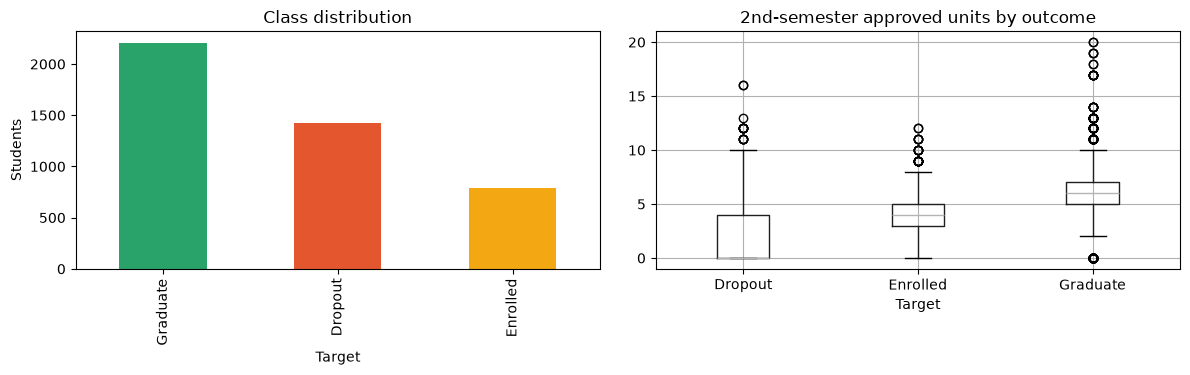

Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64
Missing values: 0


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["Target"].value_counts().plot.bar(ax=ax[0], color=["#29A36A", "#E4572E", "#F3A712"])
ax[0].set_title("Class distribution"); ax[0].set_ylabel("Students")
df.boxplot(column="Curricular units 2nd sem (approved)", by="Target", ax=ax[1])
ax[1].set_title("2nd-semester approved units by outcome"); plt.suptitle("")
plt.tight_layout(); plt.show()
print(df["Target"].value_counts(normalize=True).round(3))
print("Missing values:", int(df.isna().sum().sum()))

**Observations:** no missing values; classes are imbalanced (Graduate ≈ 50%, Dropout ≈ 32%,
Enrolled ≈ 18%). Academic progress (approved units) separates Dropout from Graduate clearly, while
*Enrolled* overlaps with both — we expect it to be the hardest class, so we report **macro-F1**
next to accuracy.

In [3]:
X = df.drop(columns="Target").astype(float)
y = df["Target"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("train:", X_tr.shape, " test:", X_te.shape)

results = []
fitted = {}
def evaluate(name, family, model):
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); secs = time.perf_counter() - t0
    pred = model.predict(X_te)
    row = {"Model": name, "Family": family, "Accuracy": accuracy_score(y_te, pred),
           "F1 (macro)": f1_score(y_te, pred, average="macro"),
           "Recall Enrolled": (pred[y_te.values == "Enrolled"] == "Enrolled").mean(),
           "Train time (s)": secs}
    results.append(row); fitted[name] = model
    print(f"{name:28s} acc={row['Accuracy']:.3f}  F1={row['F1 (macro)']:.3f}  ({secs:.1f}s)")
    return model
scaled = lambda est: make_pipeline(StandardScaler(), est)

train: (3539, 36)  test: (885, 36)


## 2. Single-model baselines

In [4]:
evaluate("Logistic Regression", "Single model", scaled(LogisticRegression(max_iter=2000, C=0.5)))
evaluate("Decision Tree", "Single model", DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=RS))
evaluate("K-Nearest Neighbors", "Single model", scaled(KNeighborsClassifier(n_neighbors=15, weights="distance")))
evaluate("Support Vector Machine", "Single model", scaled(CalibratedClassifierCV(SVC(C=1.0), ensemble=False)))
evaluate("Naive Bayes", "Single model", GaussianNB())
evaluate("Neural Network (MLP)", "Single model", scaled(MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                                     max_iter=500, early_stopping=True, random_state=RS)));

Logistic Regression          acc=0.768  F1=0.683  (0.1s)


Decision Tree                acc=0.720  F1=0.651  (0.1s)


K-Nearest Neighbors          acc=0.702  F1=0.590  (0.0s)


Support Vector Machine       acc=0.759  F1=0.679  (5.7s)
Naive Bayes                  acc=0.660  F1=0.558  (0.0s)


Neural Network (MLP)         acc=0.740  F1=0.643  (0.7s)


## 3. Bagging — Bootstrap Aggregating
Many models are trained **in parallel** on bootstrap samples of the data and their votes are
averaged. Averaging many high-variance trees **reduces variance** (less overfitting).
- `BaggingClassifier` of full-depth decision trees (classic bagging)
- **Random Forest** = bagging + random feature subset at every split (de-correlates the trees)
- **Extra Trees** = random forest with random split thresholds (even more de-correlation)

In [5]:
evaluate("Bagging (Decision Trees)", "Bagging", BaggingClassifier(DecisionTreeClassifier(random_state=RS),
                                                                  n_estimators=100, n_jobs=-1, random_state=RS))
evaluate("Random Forest", "Bagging", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                            n_jobs=-1, random_state=RS))
evaluate("Extra Trees", "Bagging", ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=RS));

Bagging (Decision Trees)     acc=0.749  F1=0.677  (10.2s)


Random Forest                acc=0.767  F1=0.680  (1.8s)


Extra Trees                  acc=0.768  F1=0.685  (0.9s)


## 4. Boosting
Weak learners are trained **sequentially**; each new tree focuses on the students the previous
trees got wrong. This **reduces bias**.
- **Gradient Boosting** (histogram-based GBM, same idea as LightGBM/XGBoost) fits each tree to the gradient of the loss
- **AdaBoost** re-weights mis-classified samples

In [6]:
evaluate("Gradient Boosting", "Boosting", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=RS))
evaluate("AdaBoost", "Boosting", AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=RS));

Gradient Boosting            acc=0.767  F1=0.698  (5.2s)


AdaBoost                     acc=0.750  F1=0.660  (4.8s)


## 5. Voting and Stacking
- **Soft voting**: average the predicted probabilities of different model types (RF + GBM + LR).
- **Stacking**: base models (RF, Extra Trees, GBM, KNN) produce out-of-fold probabilities
  (5-fold CV); a **meta-learner** (Logistic Regression) learns how to combine them.
- As in the course template, the meta-learner's `C` is tuned with **GridSearchCV**, scoring on
  **macro recall** so the minority *Enrolled* class matters.

In [7]:
evaluate("Voting (soft)", "Stacking / Voting", VotingClassifier(
    estimators=[("rf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RS)),
                ("gb", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=RS)),
                ("lr", scaled(LogisticRegression(max_iter=2000, C=0.5)))], voting="soft"))

stack = StackingClassifier(
    estimators=[("rf", RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=RS)),
                ("et", ExtraTreesClassifier(n_estimators=150, n_jobs=-1, random_state=RS)),
                ("gb", HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, random_state=RS)),
                ("knn", scaled(KNeighborsClassifier(n_neighbors=15)))],
    final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba")
evaluate("Stacking", "Stacking / Voting", stack);

Voting (soft)                acc=0.769  F1=0.694  (6.1s)


Stacking                     acc=0.774  F1=0.713  (33.9s)


In [8]:
# GridSearchCV on the stacking meta-learner (scoring = macro recall), small grid to keep it fast
grid = GridSearchCV(stack, {"final_estimator__C": [0.1, 1.0, 10.0]}, scoring="recall_macro", cv=3, n_jobs=-1)
grid.fit(X_tr, y_tr)
print("best C:", grid.best_params_, " CV macro-recall:", round(grid.best_score_, 3))
evaluate("Stacking (GridSearchCV)", "Stacking / Voting", grid.best_estimator_);

best C: {'final_estimator__C': 1.0}  CV macro-recall: 0.691


Stacking (GridSearchCV)      acc=0.774  F1=0.713  (32.1s)


## 6. Hybridization — Random Forest + ANN
The Random Forest's **out-of-fold class probabilities** (so there is no leakage) are added as 3
extra inputs to a neural network trained on the scaled original features. The forest supplies a
robust non-linear summary; the ANN learns a smooth combination of it with the raw signals.
The class lives in `model.py` (also used by the dashboard):

In [9]:
import inspect
from model import HybridRFANN
print(inspect.getsource(HybridRFANN))

class HybridRFANN(ClassifierMixin, BaseEstimator):
    """Hybrid model: Random Forest + Artificial Neural Network.

    1. A Random Forest is trained; its *out-of-fold* class probabilities on the training
       set (5-fold cross_val_predict) become 3 extra features. Out-of-fold avoids leakage:
       the ANN never sees probabilities the forest produced for rows it trained on.
    2. An MLP (ANN) is trained on the scaled original features + the RF probabilities.
    The forest contributes robust non-linear splits on the raw attributes; the ANN learns
    a smooth combination of those forest "opinions" with the original signals.
    """

    def __init__(self, n_estimators=200, hidden_layer_sizes=(32,), alpha=1.0,
                 random_state=42):
        self.n_estimators = n_estimators
        self.hidden_layer_sizes = hidden_layer_sizes
        self.alpha = alpha  # strong L2: without it the ANN over-trusts the RF features
        self.random_state = random_state

    def _rf(self):

In [10]:
evaluate("Hybrid RF + ANN", "Hybrid", HybridRFANN(random_state=RS))
# ablation: the same hybrid with weak regularisation
evaluate("Hybrid RF + ANN (alpha=0.001)", "Hybrid", HybridRFANN(hidden_layer_sizes=(64, 32), alpha=1e-3, random_state=RS));

Hybrid RF + ANN              acc=0.758  F1=0.689  (16.1s)


Hybrid RF + ANN (alpha=0.001) acc=0.687  F1=0.616  (23.7s)


## 7. Comparison of all models

In [11]:
board = pd.DataFrame(results).sort_values(["Accuracy", "F1 (macro)"], ascending=False).reset_index(drop=True)
board.index += 1
board.style.format({"Accuracy": "{:.2%}", "F1 (macro)": "{:.3f}", "Recall Enrolled": "{:.2f}", "Train time (s)": "{:.1f}"})

,Model,Family,Accuracy,F1 (macro),Recall Enrolled,Train time (s)
1,Stacking,Stacking / Voting,77.40%,0.713,0.46,33.9
2,Stacking (GridSearchCV),Stacking / Voting,77.40%,0.713,0.46,32.1
3,Voting (soft),Stacking / Voting,76.95%,0.694,0.38,6.1
4,Extra Trees,Bagging,76.84%,0.685,0.34,0.9
5,Logistic Regression,Single model,76.84%,0.683,0.33,0.1
6,Gradient Boosting,Boosting,76.72%,0.698,0.42,5.2
7,Random Forest,Bagging,76.72%,0.680,0.33,1.8
8,Support Vector Machine,Single model,75.93%,0.679,0.35,5.7
9,Hybrid RF + ANN,Hybrid,75.82%,0.689,0.41,16.1
10,AdaBoost,Boosting,75.03%,0.660,0.30,4.8


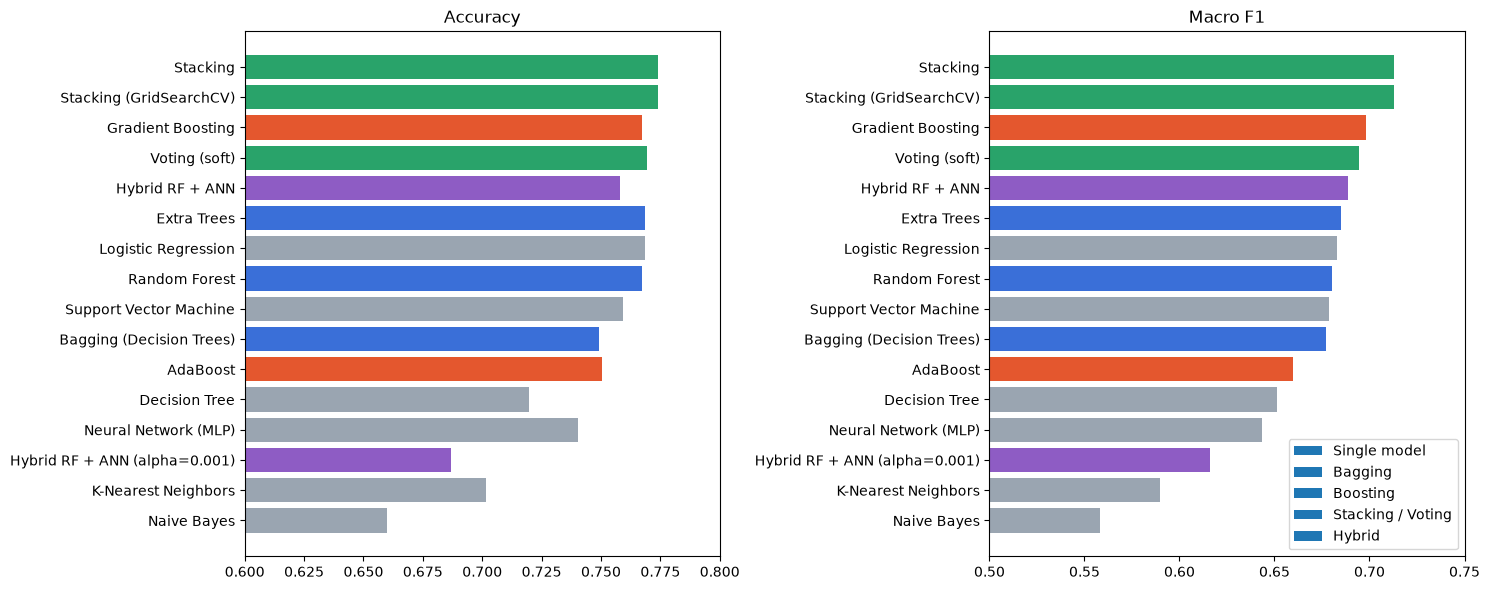

,Accuracy,F1 (macro)
Family,,
Stacking / Voting,0.774011,0.712962
Boosting,0.767232,0.697992
Hybrid,0.758192,0.688915
Bagging,0.768362,0.685183
Single model,0.768362,0.682825


In [12]:
colors = {"Single model": "#9AA5B1", "Bagging": "#3A6FD8", "Boosting": "#E4572E",
          "Stacking / Voting": "#29A36A", "Hybrid": "#8E5CC4"}
b = board.sort_values("F1 (macro)")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(b["Model"], b["Accuracy"], color=b["Family"].map(colors)); ax[0].set_xlim(0.6, 0.8); ax[0].set_title("Accuracy")
ax[1].barh(b["Model"], b["F1 (macro)"], color=b["Family"].map(colors)); ax[1].set_xlim(0.5, 0.75); ax[1].set_title("Macro F1")
for f, c in colors.items(): ax[1].barh([], [], color=c, label=f)
ax[1].legend(loc="lower right"); plt.tight_layout(); plt.show()

board.groupby("Family")[["Accuracy", "F1 (macro)"]].max().sort_values("F1 (macro)", ascending=False)

### 7.1 Robustness check — 5-fold cross-validation
A single 80/20 split can be lucky. 5-fold stratified CV on the whole dataset for the main
representatives of each family:

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
cv_models = {"Logistic Regression": scaled(LogisticRegression(max_iter=2000, C=0.5)),
             "Random Forest (bagging)": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RS),
             "Gradient Boosting (boosting)": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=RS),
             "Voting (soft)": fitted["Voting (soft)"]}
rows = []
for name, m in cv_models.items():
    s = cross_val_score(m, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"Model": name, "CV macro-F1 mean": s.mean(), "std": s.std()})
pd.DataFrame(rows).round(3)

,Model,CV macro-F1 mean,std
0,Logistic Regression,0.670,0.010
1,Random Forest (bagging),0.695,0.012
2,Gradient Boosting (boosting),0.706,0.020
3,Voting (soft),0.706,0.014


## 8. Bagging vs Boosting in detail — Random Forest vs Gradient Boosting

==================== Random Forest
              precision    recall  f1-score   support

     Dropout      0.807     0.750     0.777       284
    Enrolled      0.542     0.327     0.408       159
    Graduate      0.789     0.937     0.856       442

    accuracy                          0.767       885
   macro avg      0.712     0.671     0.680       885
weighted avg      0.750     0.767     0.750       885

==================== Gradient Boosting


              precision    recall  f1-score   support

     Dropout      0.802     0.743     0.771       284
    Enrolled      0.537     0.415     0.468       159
    Graduate      0.806     0.910     0.854       442

    accuracy                          0.767       885
   macro avg      0.715     0.689     0.698       885
weighted avg      0.756     0.767     0.758       885

==================== Stacking


              precision    recall  f1-score   support

     Dropout      0.813     0.750     0.780       284
    Enrolled      0.562     0.459     0.505       159
    Graduate      0.809     0.903     0.853       442

    accuracy                          0.774       885
   macro avg      0.728     0.704     0.713       885
weighted avg      0.766     0.774     0.767       885



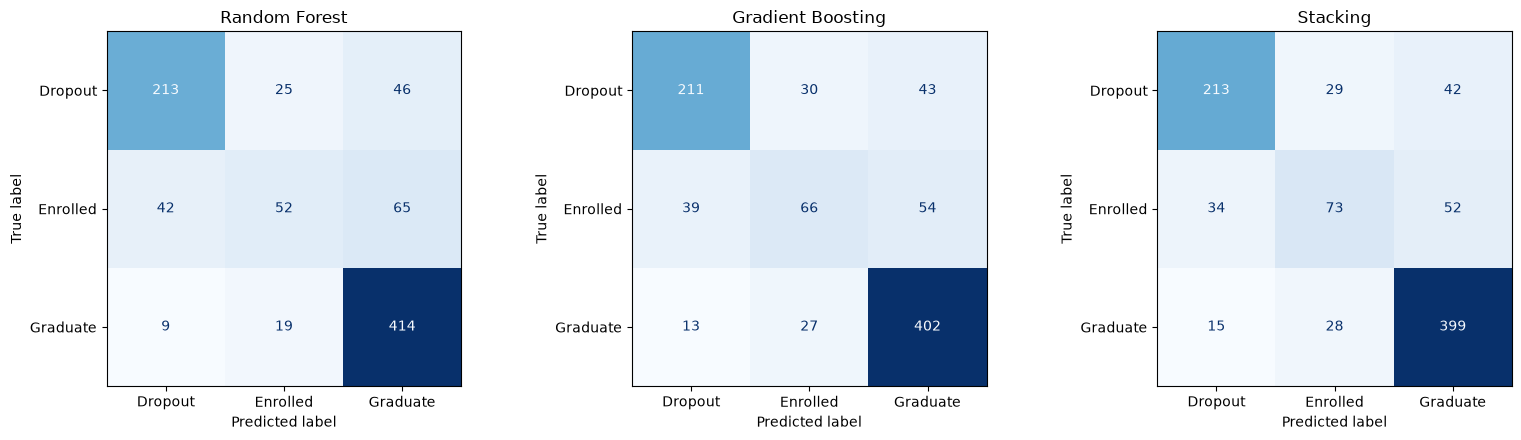

In [14]:
for name in ["Random Forest", "Gradient Boosting", "Stacking"]:
    print("=" * 20, name); print(classification_report(y_te, fitted[name].predict(X_te), digits=3))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, name in zip(ax, ["Random Forest", "Gradient Boosting", "Stacking"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_te, y_te, ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

## 9. Why do the models behave this way? — feature importance and model disagreement

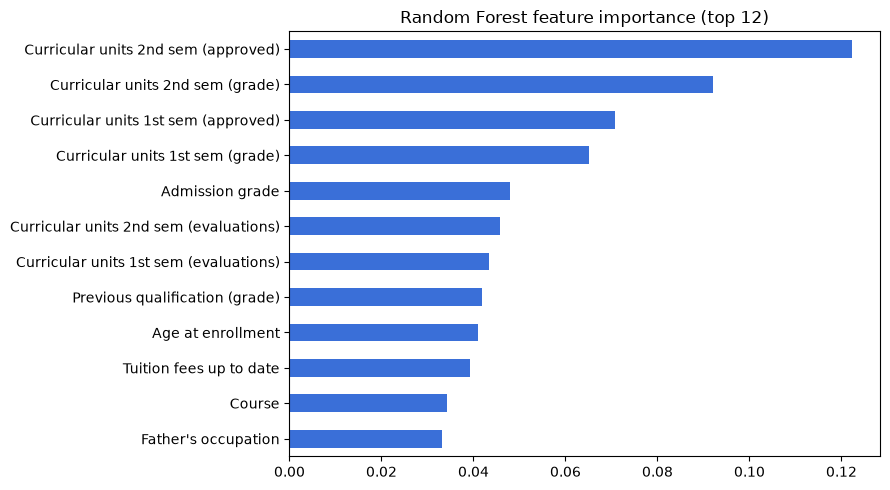

Share of test students on which two models disagree:


,Random Forest,Gradient Boosting,K-Nearest Neighbors,Logistic Regression
Random Forest,0.000,0.106,0.185,0.119
Gradient Boosting,0.106,0.000,0.214,0.151
K-Nearest Neighbors,0.185,0.214,0.000,0.203
Logistic Regression,0.119,0.151,0.203,0.000


In [15]:
imp = pd.Series(fitted["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.tail(12).plot.barh(figsize=(9, 5), color="#3A6FD8", title="Random Forest feature importance (top 12)")
plt.tight_layout(); plt.show()

names = ["Random Forest", "Gradient Boosting", "K-Nearest Neighbors", "Logistic Regression"]
preds = {n: fitted[n].predict(X_te) for n in names}
dis = pd.DataFrame([[np.mean(preds[a] != preds[b]) for b in names] for a in names], index=names, columns=names)
print("Share of test students on which two models disagree:")
dis.round(3)

## 10. Interpretation

**Bagging vs boosting.** Random Forest and Gradient Boosting reach almost the same accuracy (76.7%),
but boosting has the higher macro-F1 (0.698 vs 0.680) and clearly better recall on *Enrolled*; the
5-fold CV confirms the ranking (macro-F1 0.706 vs 0.695). Bagging trains deep trees
independently and *averages* them — this lowers variance but the average is pulled towards the
majority classes. Boosting trains trees *sequentially on the remaining errors*, which lowers bias and
concentrates on the hard, borderline students — exactly the *Enrolled* group.

**Stacking.** Stacking is the best model overall (77.4% accuracy, 0.713 macro-F1). GridSearchCV
on the meta-learner kept C = 1.0, so the default was already a good choice. Its base models disagree on a noticeable share of
students (see the disagreement matrix), so their errors are not identical; the meta-learner learns
which model to trust for which kind of student. The gain over the best single ensemble is small
because the strongest base models are all tree ensembles that agree on most students — stacking helps
most when the base models are diverse.

**Hybrid RF + ANN.** Feeding the forest's out-of-fold probabilities into an ANN lifts the ANN from
74.0% to 75.8% accuracy (macro-F1 0.643 → 0.689) and gives a slightly *higher* macro-F1 than the
Random Forest alone (0.689 vs 0.680), but a slightly *lower* accuracy (75.8% vs 76.7%). With ~3,500
training rows of tabular data the forest already captures most of the signal, so the ANN can only add
a little. The ablation is important: with weak regularisation (alpha = 0.001) the hybrid drops to
68.7% — the ANN over-trusts the RF probabilities (which are very confident on training-like data)
and overfits.

**Single models.** Naive Bayes assumes feature independence, but the 1st- and 2nd-semester features
are strongly correlated, so it is the weakest. KNN suffers from 36 mixed-scale dimensions, and a
single decision tree overfits. These are the weaknesses ensembles are designed to fix.

**What drives the prediction.** Approved curricular units and grades in the 1st and 2nd semester
dominate, followed by tuition fees being up to date and admission grade. All models can exploit
these strong signals, which is why many of them land within a few points of each other.

**Cost vs benefit.** Stacking is the most accurate but the slowest to train (it re-trains every base
model 5 times for the out-of-fold predictions). Random Forest / Extra Trees give nearly the same
accuracy in a few seconds — a good choice if training time matters.

## 11. Save the best model (pickle) for the back end

In [16]:
import joblib, os
best_name = board.iloc[0]["Model"]
os.makedirs("artifacts", exist_ok=True)
joblib.dump(fitted[best_name], "artifacts/best_model.pkl", compress=3)
print("Saved", best_name, "->", "artifacts/best_model.pkl",
      f"({os.path.getsize('artifacts/best_model.pkl') / 1e6:.1f} MB)")

Saved Stacking -> artifacts/best_model.pkl (10.8 MB)


## 12. Conclusion
Measured by macro-F1, ensemble methods beat the single-model baselines on this dataset (a
well-regularised Logistic Regression is a strong baseline on accuracy alone, but it is weaker on the
minority *Enrolled* class). **Stacking** is the best model,
**boosting** handles the difficult *Enrolled* class better than **bagging**, and the **hybrid RF + ANN**
shows that combining a forest with a neural network helps the ANN a lot but cannot beat a strong
forest on small tabular data. The same 14 models are trained live in the Streamlit dashboard, where
users can also upload their own dataset, retrain, and predict single students or whole files.

*🤖 Generated with the help of Claude (Anthropic); reviewed and run by the student.*